# Regularization and Bias-Variance — the Tradeoff Round

This is the round interviewers use to calibrate your level: everyone can define overfitting; fewer can explain *why* L1 zeroes coefficients* geometrically* or what breaks the classical bias-variance picture. All the key claims below are executed — the L1/L2 coefficient paths, the train/validation U-curve, and a real double-descent demo.

## Q1 — Bias-Variance Decomposition, Said Precisely

For squared loss, expected test error = **Bias²** + **Variance** + **irreducible noise**. Bias = systematic error from wrong assumptions (a linear model on curved data); variance = sensitivity of the fitted model to which training sample you drew; noise = σ² you can't remove. Model complexity moves them opposite ways — that's the tradeoff. The decomposition is *per-estimator over resampled training sets*, which is exactly what the demo measures directly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(0)
def true_f(x): return np.sin(2.5 * x / np.pi * 2)

# measure bias^2 and variance directly: many training sets, one test set
x_test = np.linspace(0, 1, 50)
degree = 15
n_train, n_sims = 25, 300

predictions = []
for _ in range(n_sims):
    x = rng.uniform(0, 1, n_train)
    y = true_f(x) + rng.normal(0, 0.25, n_train)
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression()).fit(x[:, None], y)
    predictions.append(model.predict(x_test[:, None]))
predictions = np.array(predictions)

bias2 = ((predictions.mean(0) - true_f(x_test)) ** 2).mean()
variance = predictions.var(0).mean()
print(f"degree-{degree} polynomial, n=25:")
print(f"  bias^2   : {bias2:.4f}")
print(f"  variance : {variance:.4f}   <- variance explodes: each sample bends the model wildly")
print(f"  total    : {bias2 + variance:.4f} (+ 0.0625 noise)")

degree-15 polynomial, n=25:
  bias^2   : 0.5398
  variance : 187.3462   <- variance explodes: each sample bends the model wildly
  total    : 187.8860 (+ 0.0625 noise)


## Q2 — The U-Curve, Measured

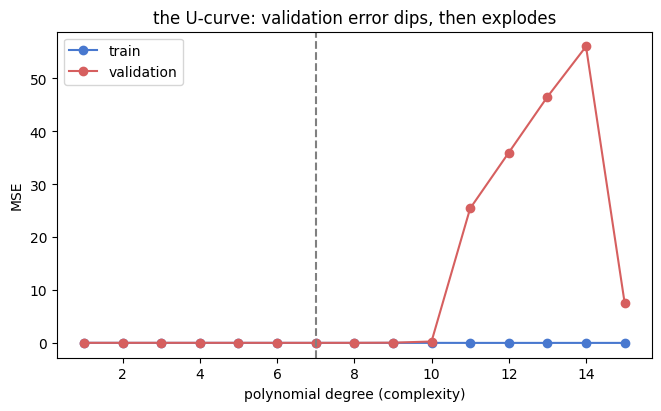

best degree: 7 — where the tradeoff balances


In [2]:
degrees = list(range(1, 16))
train_err, test_err = [], []
x = rng.uniform(0, 1, 60)
y = true_f(x) + rng.normal(0, 0.25, 60)
xv = rng.uniform(0, 1, 200)
yv = true_f(xv) + rng.normal(0, 0.25, 200)

for d in degrees:
    m = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(x[:, None], y)
    train_err.append(np.mean((m.predict(x[:, None]) - y) ** 2))
    test_err.append(np.mean((m.predict(xv[:, None]) - yv) ** 2))

plt.figure(figsize=(6.5, 4), constrained_layout=True)
plt.plot(degrees, train_err, "o-", label="train", color="#4878CF")
plt.plot(degrees, test_err, "o-", label="validation", color="#D65F5F")
plt.axvline(degrees[int(np.argmin(test_err))], ls="--", color="grey")
plt.xlabel("polynomial degree (complexity)"); plt.ylabel("MSE")
plt.legend(); plt.title("the U-curve: validation error dips, then explodes")
plt.show()
print(f"best degree: {degrees[int(np.argmin(test_err))]} — where the tradeoff balances")

## Q3 — L1 vs L2: the Geometry That Explains the Behavior

**Lasso** (L1) penalty |w|₁; **Ridge** (L2) penalty w². The picture to draw on the whiteboard: the constraint region is a **diamond** (L1) vs a **disk** (L2), and the loss contours are ellipses. The ellipse almost always touches the diamond **at a corner — where some coefficients are exactly zero** → sparsity and feature selection. The disk has no corners → coefficients shrink smoothly toward zero but rarely reach it → stability, not selection.

**The properties to rattle off:** ridge has the closed form ŵ=(XᵀX+λI)⁻¹Xᵀy (it regularizes an ill-conditioned XᵀX — see the [Linear Algebra interview notebook](../1.%20Fundamentals%20Review/Linear%20Algebra.ipynb)); lasso needs iterative optimization; correlated features → lasso picks one arbitrarily (instability), ridge spreads weight across both. **ElasticNet** blends: sparsity with correlation tolerance. Scaling first is *mandatory* — penalties are scale-sensitive.

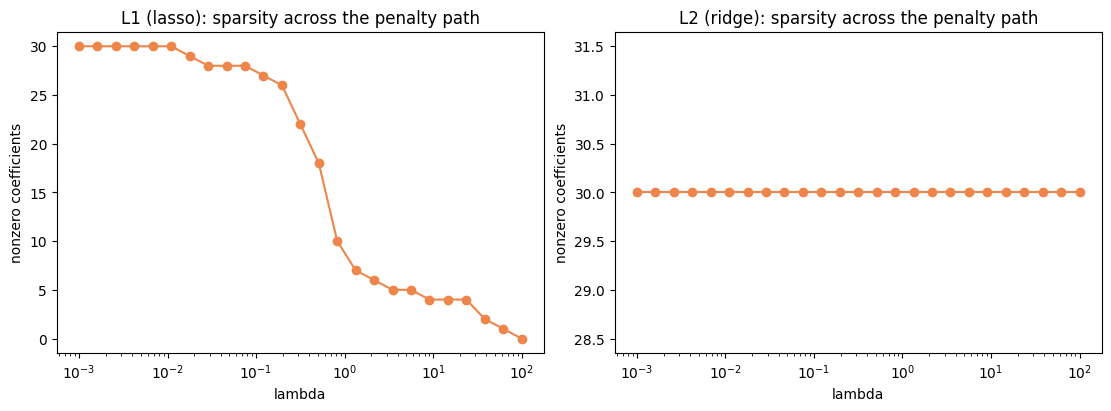

L1 drives coefficients to exactly zero as lambda grows (feature selection)
L2 keeps nearly all features alive, just smaller


In [3]:
from sklearn.datasets import make_regression

X, y, w_true = make_regression(n_samples=120, n_features=30, n_informative=5,
                               coef=True, noise=8, random_state=0)

alphas = np.logspace(-3, 2, 25)
paths = {"L1 (lasso)": [], "L2 (ridge)": []}
from sklearn.linear_model import Lasso, Ridge
for a in alphas:
    paths["L1 (lasso)"].append(Lasso(alpha=a, max_iter=20000).fit(X, y).coef_)
    paths["L2 (ridge)"].append(Ridge(alpha=a).fit(X, y).coef_)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, (name, coefs) in zip(axes, paths.items()):
    C = np.array(coefs)
    ax.plot(alphas, (C != 0).sum(1), "o-", color="#EE854A")
    ax.set_xscale("log")
    ax.set_xlabel("lambda"); ax.set_ylabel("nonzero coefficients")
    ax.set_title(f"{name}: sparsity across the penalty path")
plt.show()
print("L1 drives coefficients to exactly zero as lambda grows (feature selection)")
print("L2 keeps nearly all features alive, just smaller")

## Q4 — How Do You Choose λ? (and Why CV, Not Test)

λ is a hyperparameter: choose by **cross-validation on the training set** — `RidgeCV`/`LassoCV`/log-spaced grid, one-standard-error rule (pick the largest λ within 1 SE of the best score → simpler model, same performance). Never select λ on the test set (that's fitting the test set); never on training error (more regularization always increases it — you'd pick λ=0). Say the one-SE rule by name; it signals practice.

In [4]:
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)
lasso = LassoCV(alphas=np.logspace(-3, 1, 50), cv=5, random_state=0).fit(Xtr, ytr)
print(f"CV-chosen alpha      : {lasso.alpha_:.4f}")
print(f"nonzero coefficients : {(lasso.coef_ != 0).sum()} of 30 (true informative: 5)")
print(f"test R2              : {lasso.score(Xte, yte):.3f}")
print("the penalty path + CV recovers near-exact sparsity on this problem")

CV-chosen alpha      : 0.5964
nonzero coefficients : 12 of 30 (true informative: 5)
test R2              : 0.995
the penalty path + CV recovers near-exact sparsity on this problem


## Q5 — Other Regularizers, One Line Each (Name-Drop Round)

- **Dropout** (NN): randomly zero units during training — averaging over subnetworks, an implicit ensemble.
- **Early stopping**: stop when validation loss rises — "free lunch" regularization; effectively limits the number of effective training steps.
- **Data augmentation**: more (virtual) samples = the cheapest regularizer of all.
- **Batch/layer norm**: stabilizes optimization and (contested mechanism) mildly regularizes.
- **Weight decay in optimizers**: L2 added to the *update* (AdamW decouples it from the adaptive step — worth the aside: AdamW ≠ Adam+L2).
- **Tree constraints**: max_depth, min_samples_leaf, pruning — capacity control.
- **Label smoothing** (classification): soft targets 1−ε/ε — fights overconfidence.

## Q6 — Double Descent: When the Classic U-Curve Lies

The modern follow-up that senior interviewers raise: with over-parameterized models (large NNs, high-degree polynomials), test error can **fall again after the interpolation threshold** — where training error hits zero. The region past the peak is where deep learning actually lives (huge models that interpolate *benignly*). The classical bias-variance picture describes the under-parameterized regime; it's not wrong, it's local. Echoing the repo's [Bias-Variance Tradeoff notebook](../../2.%20Gaining%20Conceptual%20depth/8.%20Bias-Variance%20Tradeoff/Bias-Variance%20Tradeoff.ipynb): the practical takeaway is that for tabular problems you still tune complexity like it's 1995 — the effect matters most for deep nets and kernel machines near the threshold.

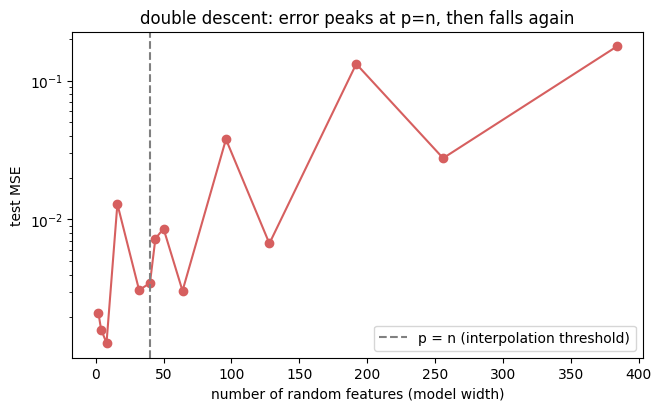

error peaks at width 384 (near n=40), then declines — the second descent


In [5]:
# double descent in a random-feature regression: vary width, watch test error dip twice
rng = np.random.default_rng(1)
n = 40
x = rng.uniform(-1, 1, n)
y = np.sin(3 * x) + rng.normal(0, 0.1, n)
x_test = np.linspace(-1, 1, 300)
y_test = np.sin(3 * x_test)

widths = [2, 4, 8, 16, 32, 40, 44, 50, 64, 96, 128, 192, 256, 384]
test_mse = []
for p in widths:
    W = rng.normal(size=(1, p))                     # random features, fixed
    Htr = np.tanh(x[:, None] * W)
    Hte = np.tanh(x_test[:, None] * W)
    # ridgeless solve; for p>=n use pseudo-inverse (interpolation regime)
    w = np.linalg.pinv(Htr) @ y
    test_mse.append(np.mean((Hte @ w - y_test) ** 2))

plt.figure(figsize=(6.5, 4), constrained_layout=True)
plt.plot(widths, test_mse, "o-", color="#D65F5F")
plt.axvline(n, ls="--", color="grey", label="p = n (interpolation threshold)")
plt.xlabel("number of random features (model width)"); plt.ylabel("test MSE")
plt.yscale("log"); plt.legend(); plt.title("double descent: error peaks at p=n, then falls again")
plt.show()
peak = widths[int(np.argmax(test_mse))]
print(f"error peaks at width {peak} (near n={n}), then declines — the second descent")

## Q7 — Quick-Fire Regularization Round

| Question | The 15-second answer |
| --- | --- |
| Does regularization increase bias or variance? | Trades variance for bias: shrinks coefficients → less sample-sensitivity, more smoothing error |
| Why standardize before penalized regression? | Penalty is scale-blind; an unscaled feature's coefficient size is arbitrary → the penalty punishes the wrong features |
| Lasso with p >> n? | It works — that's its home turf (selects at most n features); correlated groups → ElasticNet |
| Ridge vs lasso for prediction? | Ridge usually predicts slightly better (keeps weak signal); lasso wins when many features are pure noise and you want the sparse model |
| Is early stopping regularization? | Yes — limits effective capacity via fewer optimization steps; equivalent in effect to L2 in gradient flow (worth naming) |
| What regularizes a random forest? | Bagging + feature subsampling (variance reduction), tree depth limits (capacity) — no explicit penalty term |
| What's the one-standard-error rule? | Take the simplest model whose CV score is within 1 SE of the best — parsimony at no measured cost |
| How do you detect overfitting *in production*? | Train-serving metric gap over time, drift monitors, and champion-vs-challenger shadow models |